# FUNDAMENTALS OF DATA SCIENCE — CASE STUDY 1

## Online Retail Transaction Clustering

**Name:** Shravani Kandikonda  
**Roll Number:** 160124733146  
**Section:** CSE-3  
**Year:** III Year B.E.  
**Subject:** Fundamentals of Data Science  
**Faculty:** Smt. S. Durga Devi  
**Department:** Computer Science and Engineering  
**Institution:** Chaitanya Bharathi Institute of Technology (CBIT)

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, davies_bouldin_score
from IPython.display import display
DATA = Path('/content/Online retail_new.csv')


## Methodology and results
All figures are labelled and saved as PNG. Outputs are generated from the supplied data.

Transactions: 7501 Missing cells: 120657 Duplicate baskets: 2347
Top 15 products:


,Product,Frequency
0,mineral water,1788
1,eggs,1348
2,spaghetti,1306
3,french fries,1282
4,chocolate,1229
5,green tea,991
6,milk,972
7,ground beef,737
8,frozen vegetables,715
9,pancakes,713


Basket size statistics:


,0
count,7501.000000
mean,3.913878
std,2.904901
min,1.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,20.000000


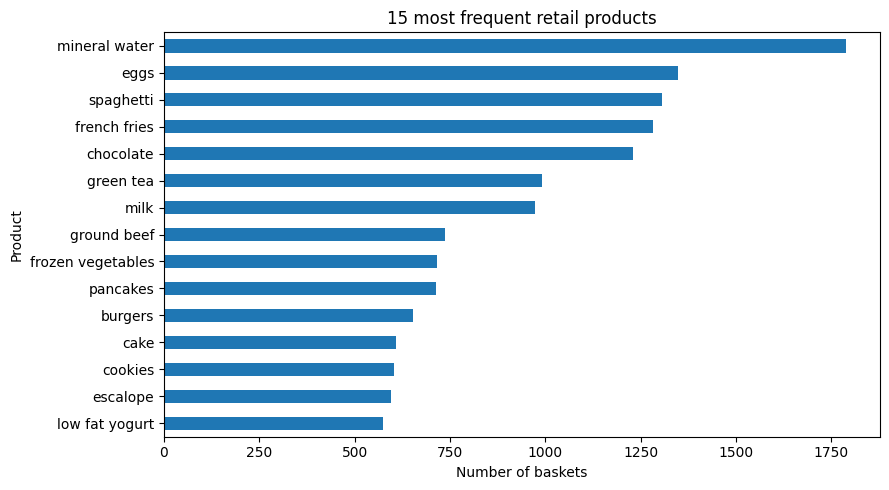

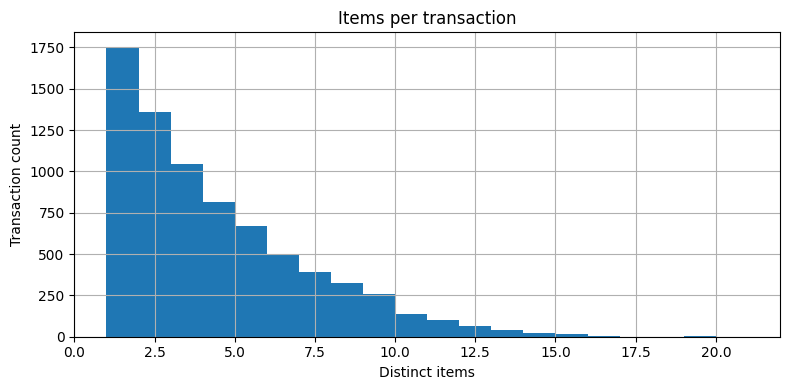

Explained variance by two PCA components: [0.1074 0.0776]


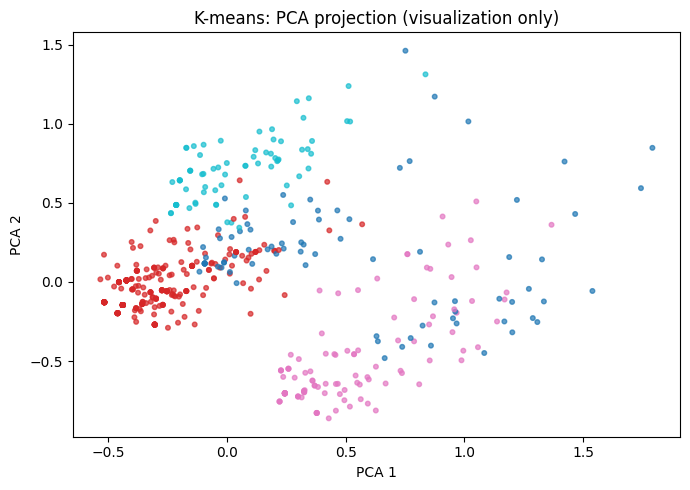

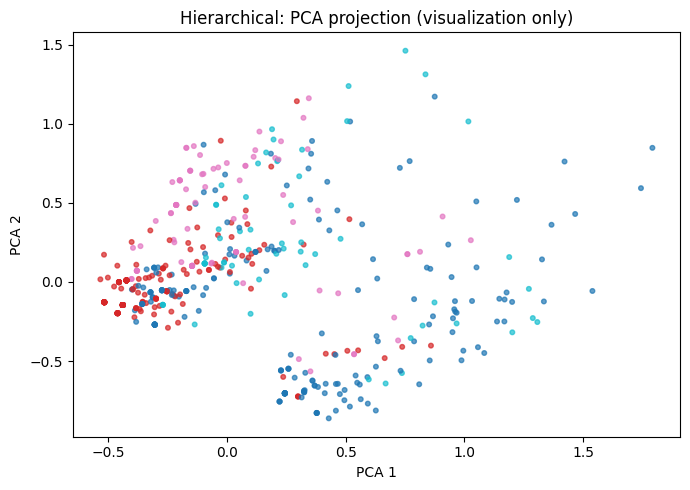

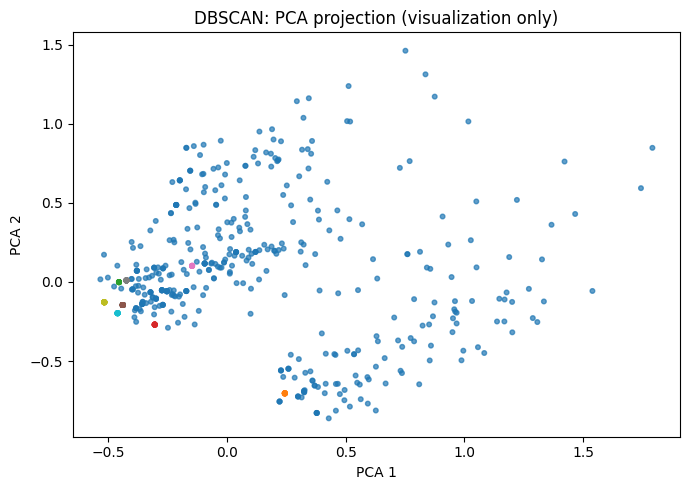

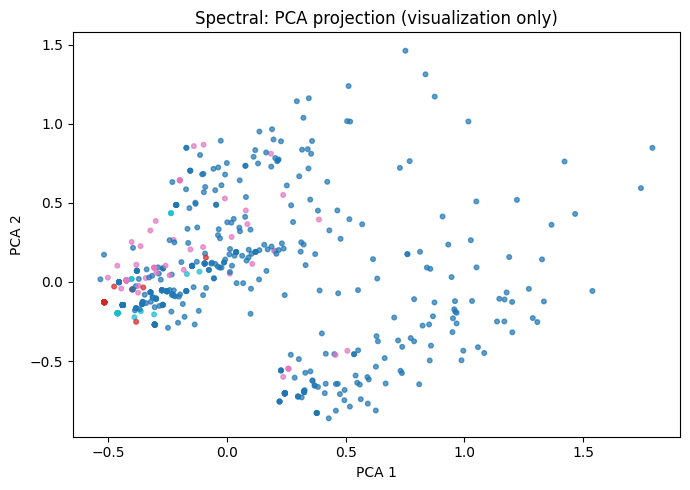

,Algorithm,Clusters,Noise,Silhouette,Davies-Bouldin
0,K-means,4,0,0.157842,2.416483
1,Hierarchical,4,0,0.058756,3.526605
2,DBSCAN,8,420,1.000000,0.000000
3,Spectral,4,0,-0.000233,1.942468


Interpretation: Higher silhouette and lower Davies-Bouldin generally indicate better separation; scores exclude DBSCAN noise. PCA is used for visualization, while clustering and scoring use binary product indicators. Product frequency and basket size reveal demand patterns, but clusters are sensitive to feature selection, sample and parameter choices.


In [2]:
# Transaction clustering: verified analysis of the provided retail CSV
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
raw=pd.read_csv(DATA,header=None,encoding='latin1')
transactions=[[str(x).strip().lower() for x in row if pd.notna(x) and str(x).strip()] for row in raw.to_numpy()]
transactions=[list(dict.fromkeys(t)) for t in transactions if t]
print('Transactions:',len(transactions),'Missing cells:',raw.isna().sum().sum(),'Duplicate baskets:',len(transactions)-len(set(tuple(sorted(t)) for t in transactions)))
from collections import Counter
freq=Counter(x for t in transactions for x in t)
print('Top 15 products:');display(pd.DataFrame(freq.most_common(15),columns=['Product','Frequency']))
sizes=pd.Series([len(t) for t in transactions]);print('Basket size statistics:');display(sizes.describe().to_frame())
fig,ax=plt.subplots(figsize=(9,5));pd.Series(dict(freq.most_common(15))).sort_values().plot.barh(ax=ax);ax.set(title='15 most frequent retail products',xlabel='Number of baskets',ylabel='Product');plt.tight_layout();plt.savefig('products.png');plt.show()
fig,ax=plt.subplots(figsize=(8,4));sizes.hist(bins=range(1,int(sizes.max())+2),ax=ax);ax.set(title='Items per transaction',xlabel='Distinct items',ylabel='Transaction count');plt.tight_layout();plt.savefig('basket_sizes.png');plt.show()
# Limit to 25 most common items; sparse high-dimensional baskets are otherwise difficult to compare.
selected=[x for x,n in freq.most_common(25)]
X=np.array([[int(x in t) for x in selected] for t in transactions],dtype=np.float32)
# Sample reproducibly to make spectral and hierarchical algorithms feasible on laptops.
rng=np.random.default_rng(42);indices=np.sort(rng.choice(len(X),size=min(600,len(X)),replace=False));Xs=X[indices]
pca=PCA(n_components=2,random_state=42);Z=pca.fit_transform(Xs)
print('Explained variance by two PCA components:',np.round(pca.explained_variance_ratio_,4))
models={'K-means':KMeans(n_clusters=4,n_init=10,random_state=42),'Hierarchical':AgglomerativeClustering(n_clusters=4),'DBSCAN':DBSCAN(eps=0.8,min_samples=8),'Spectral':SpectralClustering(n_clusters=4,affinity='nearest_neighbors',n_neighbors=12,random_state=42)}
rows=[]
for name,model in models.items():
 labels=model.fit_predict(Xs);valid=labels!=-1;unique=np.unique(labels[valid]);noise=int((~valid).sum())
 if len(unique)>1 and valid.sum()>len(unique):
  sil=silhouette_score(Xs[valid],labels[valid]);db=davies_bouldin_score(Xs[valid],labels[valid])
 else:sil=np.nan;db=np.nan
 rows.append({'Algorithm':name,'Clusters':len(unique),'Noise':noise,'Silhouette':sil,'Davies-Bouldin':db})
 fig,ax=plt.subplots(figsize=(7,5));ax.scatter(Z[:,0],Z[:,1],c=labels,s=11,cmap='tab10',alpha=.7);ax.set(title=f'{name}: PCA projection (visualization only)',xlabel='PCA 1',ylabel='PCA 2');plt.tight_layout();plt.savefig(name.lower().replace('-','_')+'.png');plt.show()
results=pd.DataFrame(rows);display(results);results.to_csv('clustering_results.csv',index=False)
print('Interpretation: Higher silhouette and lower Davies-Bouldin generally indicate better separation; scores exclude DBSCAN noise. PCA is used for visualization, while clustering and scoring use binary product indicators. Product frequency and basket size reveal demand patterns, but clusters are sensitive to feature selection, sample and parameter choices.')
